# Emotion Classification with Attention: LSTM vs GRU vs BiLSTM + Attention vs Fine-tuned DistilBERT

A six-class emotion classifier (joy, sadness, anger, fear, surprise, disgust) trained on GoEmotions. Three recurrent models built from scratch use pretrained GloVe embeddings, and one of them adds attention over its hidden states so the words that drive each prediction can be visualized. DistilBERT is fine-tuned with the HuggingFace Trainer and compared against them, and the best model is deployed with Gradio.

## 1. Setup and settings
Enable a GPU and Internet in Kaggle (needed for the dataset, GloVe, and the transformer weights).

In [1]:
import os, sys, re, io, json, math, time, copy, html, random, inspect, subprocess, warnings, urllib.request
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.utils.class_weight import compute_class_weight
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

warnings.filterwarnings("ignore")
T0 = time.time()

SEED = 42
GLOVE_NAME = "glove-wiki-gigaword-100"
MAX_LEN = 40
HIDDEN = 128
ATT_DIM = 64
DROPOUT = 0.4
BATCH = 64
EPOCHS = 15
LR = 1e-3
PATIENCE = 4

TRANSFORMER_NAME = "distilbert-base-uncased"
TR_EPOCHS = 3
TR_LR = 5e-5
TR_BATCH = 32
TR_MAX_LEN = 64

EMOTIONS = ["joy", "sadness", "anger", "fear", "surprise", "disgust"]
EMOTION_COLORS = {"joy": "#f4c542", "sadness": "#4c78d0", "anger": "#d9534f", "fear": "#8e5bb5", "surprise": "#f0883e", "disgust": "#5fa55a"}
NUM_CLASSES = len(EMOTIONS)
EMOTION_TO_ID = {e: i for i, e in enumerate(EMOTIONS)}

CUDA = torch.cuda.is_available()
device = torch.device("cuda" if CUDA else "cpu")
WORK = Path("/kaggle/working") if Path("/kaggle").exists() else Path("./working")
WORK.mkdir(parents=True, exist_ok=True)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)
print("device:", torch.cuda.get_device_name(0) if CUDA else "CPU only (enable a GPU in Kaggle!)")

device: Tesla T4


## 2. Load and explore GoEmotions
The simplified configuration of `google-research-datasets/go_emotions` has about 58 thousand Reddit comments with predefined train, validation, and test splits. Each comment has one or more labels out of 27 fine-grained emotions plus neutral.

README.md:   0%|          | 0.00/9.40k [00:00<?, ?B/s]

simplified/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.77MB            

simplified/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

simplified/validation-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B /  350kB            

simplified/validation-00000-of-00001.par(…): downloading bytes:           |  0.00B            

simplified/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  347kB            

... (2 outputs left out)

Generating validation split:   0%|          | 0/5426 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5427 [00:00<?, ? examples/s]

label names: 28 | neutral id: 27


,comments,avg labels per comment,with more than one label,avg words
train,43410,1.18,16.4%,12.8
validation,5426,1.18,16.2%,12.8
test,5427,1.17,15.4%,12.7


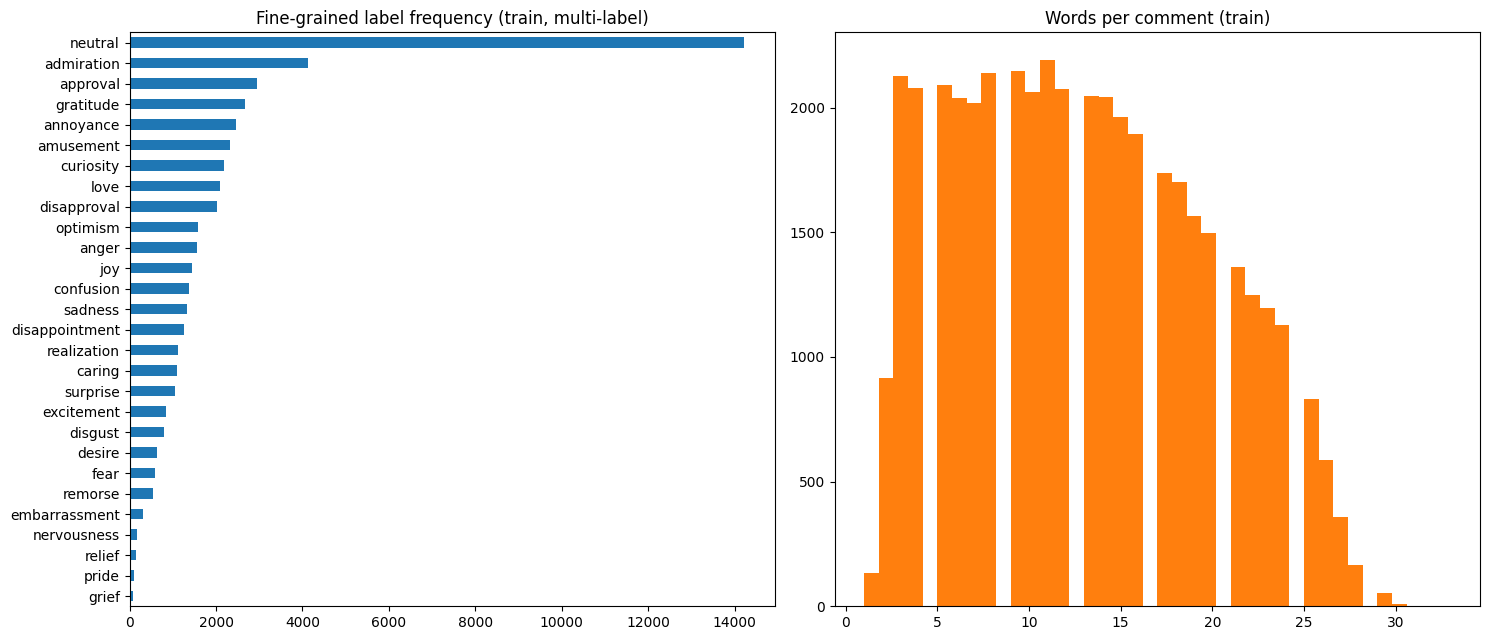

['neutral'] | The only way this works is if [NAME] is doing the Bird Box challenge and cant see the terms of the contract.
['annoyance'] | Access should be hindered it's getting destroyed.
['approval'] | Totally fair. All I was trying to remind everyone is don't fall in love with your crushes.
['surprise'] | I'm poly and jn the Raleigh area too, moved here for my wife's job, surprised to find so many people mention i
['amusement'] | Naw man Asain men have an easier time. Most of my asain friend are pretty boy. Fuckbois lol
['fear'] | That scene traumatized me the first time I watched it


In [2]:
from datasets import load_dataset

FALLBACK_LABELS = ["admiration", "amusement", "anger", "annoyance", "approval", "caring", "confusion", "curiosity", "desire",
                   "disappointment", "disapproval", "disgust", "embarrassment", "excitement", "fear", "gratitude", "grief", "joy",
                   "love", "nervousness", "optimism", "pride", "realization", "relief", "remorse", "sadness", "surprise", "neutral"]

def load_goemotions():
    last_error = None
    for kwargs in ({}, {"revision": "refs/convert/parquet"}):
        try:
            return load_dataset("google-research-datasets/go_emotions", "simplified", **kwargs)
        except Exception as error:
            last_error = error
            print("load attempt failed:", str(error)[:150])
    raise RuntimeError(f"Could not load GoEmotions: {last_error}")

dataset = load_goemotions()
try:
    label_names = list(dataset["train"].features["labels"].feature.names)
except Exception:
    label_names = FALLBACK_LABELS
print("label names:", len(label_names), "| neutral id:", label_names.index("neutral"))

raw_frames = {split: pd.DataFrame({"text": dataset[split]["text"], "labels": [list(l) for l in dataset[split]["labels"]]})
              for split in ("train", "validation", "test")}
display(pd.DataFrame({split: {"comments": len(f), "avg labels per comment": round(f["labels"].str.len().mean(), 2),
                              "with more than one label": f"{(f['labels'].str.len() > 1).mean():.1%}",
                              "avg words": round(f["text"].str.split().str.len().mean(), 1)} for split, f in raw_frames.items()}).T)

label_counts = Counter(label_names[i] for labels in raw_frames["train"]["labels"] for i in labels)
ordered = pd.Series(label_counts).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
ordered.plot.barh(ax=axes[0], color="tab:blue")
axes[0].set_title("Fine-grained label frequency (train, multi-label)")
axes[1].hist(raw_frames["train"]["text"].str.split().str.len().clip(upper=40), bins=40, color="tab:orange")
axes[1].set_title("Words per comment (train)")
plt.tight_layout()
plt.show()

for text, labels in raw_frames["train"].sample(6, random_state=SEED).itertuples(index=False):
    print([label_names[i] for i in labels], "|", text[:110])

## 3. Map the 28 raw labels to the 6 target emotions
The fine-grained labels are grouped into the six Ekman emotions with the mapping published with GoEmotions (the cell downloads the official `ekman_mapping.json` and falls back to a built-in copy). A comment is kept as a single-label example only when all its emotion labels fall into the same target emotion. Comments that are neutral only (no target emotion) or that mix several target emotions are removed, because they have no single correct class among the six.

mapping source: official GoEmotions ekman_mapping.json


,GoEmotions labels
joy,"joy, amusement, approval, excitement, gratitud..."
sadness,"sadness, disappointment, embarrassment, grief,..."
anger,"anger, annoyance, disapproval"
fear,"fear, nervousness"
surprise,"surprise, realization, confusion, curiosity"
disgust,disgust


,comments,neutral only (removed),mixed emotions (removed),kept
train,43410,12823,2483,28104
validation,5426,1592,307,3527
test,5427,1606,282,3539


,train,validation,test,train %
emotion,,,,
joy,15809,2017,1937,56.3
sadness,2455,278,298,8.7
anger,4590,596,609,16.3
fear,566,77,85,2.0
surprise,4160,497,533,14.8
disgust,524,62,77,1.9


imbalance ratio in train (largest / smallest class): 30.2


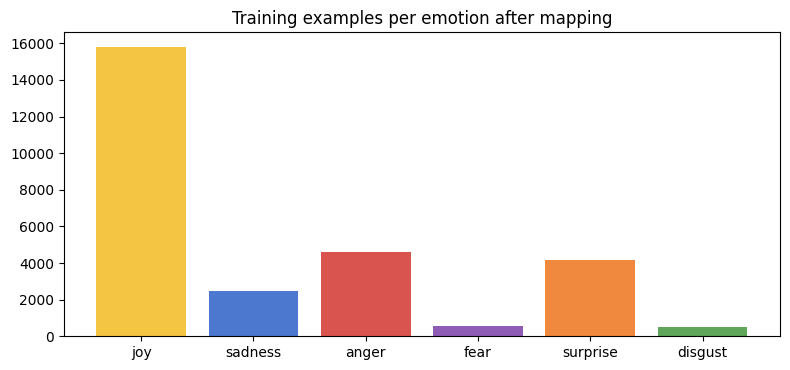

In [3]:
EKMAN_BUILTIN = {
    "anger": ["anger", "annoyance", "disapproval"],
    "disgust": ["disgust"],
    "fear": ["fear", "nervousness"],
    "joy": ["joy", "amusement", "approval", "excitement", "gratitude", "love", "optimism", "relief", "pride", "admiration", "desire", "caring"],
    "sadness": ["sadness", "disappointment", "embarrassment", "grief", "remorse"],
    "surprise": ["surprise", "realization", "confusion", "curiosity"],
}
EKMAN_URL = "https://raw.githubusercontent.com/google-research/google-research/master/goemotions/data/ekman_mapping.json"

def load_ekman_mapping():
    try:
        with urllib.request.urlopen(EKMAN_URL, timeout=30) as response:
            official = json.loads(response.read().decode("utf-8"))
        if {k: sorted(v) for k, v in official.items()} != {k: sorted(v) for k, v in EKMAN_BUILTIN.items()}:
            print("note: the official mapping differs from the built-in copy, the official one is used")
        return official, "official GoEmotions ekman_mapping.json"
    except Exception as error:
        print("could not download the official mapping, using the built-in copy:", str(error)[:100])
        return EKMAN_BUILTIN, "built-in copy"

ekman_mapping, mapping_source = load_ekman_mapping()
assert set(ekman_mapping) == set(EMOTIONS), set(ekman_mapping)
label_to_emotion = {label: emotion for emotion, labels in ekman_mapping.items() for label in labels}
unmapped = [n for n in label_names if n not in label_to_emotion and n != "neutral"]
assert not unmapped, unmapped
print("mapping source:", mapping_source)
display(pd.DataFrame({"GoEmotions labels": {e: ", ".join(ekman_mapping[e]) for e in EMOTIONS}}))

def to_emotion(label_ids):
    emotions = {label_to_emotion[label_names[i]] for i in label_ids if label_names[i] in label_to_emotion}
    if not emotions:
        return None, "neutral only"
    if len(emotions) > 1:
        return None, "mixed emotions"
    return next(iter(emotions)), "kept"

frames, status_rows = {}, {}
for split, frame in raw_frames.items():
    mapped = [to_emotion(labels) for labels in frame["labels"]]
    frame = frame.assign(emotion=[m[0] for m in mapped], status=[m[1] for m in mapped])
    counts = frame["status"].value_counts()
    status_rows[split] = {"comments": len(frame), "neutral only (removed)": int(counts.get("neutral only", 0)),
                          "mixed emotions (removed)": int(counts.get("mixed emotions", 0)), "kept": int(counts.get("kept", 0))}
    frames[split] = frame[frame["status"] == "kept"].drop(columns=["labels", "status"]).reset_index(drop=True)
display(pd.DataFrame(status_rows).T)

distribution = pd.DataFrame({split: f["emotion"].value_counts() for split, f in frames.items()}).loc[EMOTIONS]
distribution["train %"] = (distribution["train"] / distribution["train"].sum() * 100).round(1)
display(distribution)
print(f"imbalance ratio in train (largest / smallest class): {distribution['train'].max() / distribution['train'].min():.1f}")
fig, axis = plt.subplots(figsize=(8, 3.8))
axis.bar(EMOTIONS, distribution["train"], color=[EMOTION_COLORS[e] for e in EMOTIONS])
axis.set_title("Training examples per emotion after mapping")
plt.tight_layout()
plt.show()

## 4. Clean and tokenize the text
Text is lowercased, URLs and the `[NAME]` and `[RELIGION]` placeholders are removed, contractions are split the way GloVe expects (`don't` becomes `do n't`), and the text is tokenized into words. The exclamation and question marks are kept as tokens because they carry emotional signal. Duplicate comments are removed, and any validation or test comment that also appears in the training set is dropped so that no sentence is seen in training and evaluation.

In [4]:
URL_RE = re.compile(r"https?://\S+|www\.\S+")
PLACEHOLDER_RE = re.compile(r"\[(?:name|religion)\]")
TOKEN_RE = re.compile(r"n't|'(?:s|m|re|ve|ll|d)\b|[a-z]+|[!?]")

def clean_tokens(text):
    text = PLACEHOLDER_RE.sub(" ", URL_RE.sub(" ", text.lower()))
    return TOKEN_RE.findall(text.replace("n't", " n't"))

for split in frames:
    frame = frames[split]
    frame["tokens"] = [clean_tokens(t) for t in frame["text"]]
    frame = frame[frame["tokens"].str.len() >= 1]
    frame = frame.assign(key=frame["tokens"].str.join(" ")).drop_duplicates("key")
    frames[split] = frame

before = {s: len(f) for s, f in frames.items()}
train_keys = set(frames["train"]["key"])
frames["validation"] = frames["validation"][~frames["validation"]["key"].isin(train_keys)]
frames["test"] = frames["test"][~frames["test"]["key"].isin(train_keys | set(frames["validation"]["key"]))]
for split in frames:
    frames[split] = frames[split].reset_index(drop=True)
    frames[split]["y"] = frames[split]["emotion"].map(EMOTION_TO_ID)
    print(f"{split}: {before[split]} after cleaning and duplicate removal -> {len(frames[split])} after removing overlap with earlier splits")
train, val, test = frames["train"], frames["validation"], frames["test"]
y_train, y_val, y_test = (f["y"].to_numpy().astype(np.int64) for f in (train, val, test))

class_weight_values = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=y_train)
class_weights = torch.tensor(class_weight_values, dtype=torch.float32)
display(pd.DataFrame({"train": np.bincount(y_train, minlength=NUM_CLASSES), "validation": np.bincount(y_val, minlength=NUM_CLASSES),
                      "test": np.bincount(y_test, minlength=NUM_CLASSES), "class weight": class_weight_values.round(2)}, index=EMOTIONS))

lengths_all = train["tokens"].str.len()
print(f"tokens per comment: median {int(lengths_all.median())}, 95th percentile {int(lengths_all.quantile(0.95))}, 99th percentile {int(lengths_all.quantile(0.99))}")
print(f"comments longer than MAX_LEN={MAX_LEN}: {(lengths_all > MAX_LEN).mean():.2%}")
for i in range(3):
    row = train.iloc[i]
    print(f"\n{row['emotion'].upper()}\n  original: {row['text'][:120]}\n  tokens  : {row['tokens'][:20]}")

train: 27780 after cleaning and duplicate removal -> 27780 after removing overlap with earlier splits
validation: 3513 after cleaning and duplicate removal -> 3459 after removing overlap with earlier splits
test: 3528 after cleaning and duplicate removal -> 3474 after removing overlap with earlier splits


,train,validation,test,class weight
joy,15545,1964,1882,0.30
sadness,2439,275,293,1.90
anger,4568,592,607,1.01
fear,565,76,84,8.19
surprise,4141,491,531,1.12
disgust,522,61,77,8.87


tokens per comment: median 13, 95th percentile 25, 99th percentile 28
comments longer than MAX_LEN=40: 0.00%

ANGER
  original: WHY THE FUCK IS BAYLESS ISOING
  tokens  : ['why', 'the', 'fuck', 'is', 'bayless', 'isoing']

FEAR
  original: To make her feel threatened
  tokens  : ['to', 'make', 'her', 'feel', 'threatened']

ANGER
  original: Dirty Southern Wankers
  tokens  : ['dirty', 'southern', 'wankers']


## 5. Load pretrained GloVe vectors and build the vocabulary
The vocabulary contains every training word plus the validation and test words that GloVe knows, so unseen words that GloVe has a vector for still get a meaningful representation.

In [5]:
def read_glove_txt(path):
    words, vectors = [], []
    with open(path, encoding="utf-8") as file:
        for line in file:
            parts = line.rstrip().split(" ")
            if len(parts) > 10:
                words.append(parts[0])
                vectors.append(np.asarray(parts[1:], dtype=np.float32))
    return {w: i for i, w in enumerate(words)}, np.vstack(vectors)

def load_glove():
    root = Path("/kaggle/input")
    if root.exists():
        files = sorted(root.rglob("glove*100d*.txt")) or sorted(root.rglob("glove*.txt"))
        if files:
            print("GloVe file:", files[0])
            return read_glove_txt(files[0])
    try:
        import gensim.downloader as downloader
        vectors = downloader.load(GLOVE_NAME)
        return dict(vectors.key_to_index), np.asarray(vectors.vectors, dtype=np.float32)
    except Exception as error:
        print("gensim download failed:", str(error)[:120])
    from huggingface_hub import snapshot_download
    from gensim.models import KeyedVectors
    folder = Path(snapshot_download("fse/glove-wiki-gigaword-100"))
    vectors = KeyedVectors.load(str(next(folder.glob("*.model"))))
    return dict(vectors.key_to_index), np.asarray(vectors.vectors, dtype=np.float32)

glove_index, glove_matrix = load_glove()
EMBED_DIM = glove_matrix.shape[1]
print(f"GloVe: {len(glove_index):,} words, {EMBED_DIM} dimensions")

PAD, UNK = 0, 1
train_words = {w for tokens in train["tokens"] for w in tokens}
extra_words = {w for split in (val, test) for tokens in split["tokens"] for w in tokens if w in glove_index}
vocabulary = ["<pad>", "<unk>"] + sorted(train_words | extra_words)
word_index = {w: i for i, w in enumerate(vocabulary)}

rng = np.random.default_rng(SEED)
embedding_matrix = rng.normal(0, 0.1, size=(len(vocabulary), EMBED_DIM)).astype(np.float32)
embedding_matrix[PAD] = 0.0
found = 0
for word, i in word_index.items():
    row = glove_index.get(word)
    if row is not None:
        embedding_matrix[i] = glove_matrix[row]
        found += 1
print(f"vocabulary: {len(vocabulary):,} words | initialized from GloVe: {found:,} ({found / len(vocabulary):.1%})")

coverage = {name: np.mean([w in glove_index for tokens in split["tokens"] for w in tokens]) for name, split in (("train", train), ("validation", val), ("test", test))}
print("tokens covered by GloVe:", {k: f"{v:.1%}" for k, v in coverage.items()})
missing = Counter(w for tokens in train["tokens"] for w in tokens if w not in glove_index).most_common(12)
print("most frequent training words without a GloVe vector:", missing)

[==================================================] 100.0% 128.1/128.1MB downloaded
GloVe: 400,000 words, 100 dimensions
vocabulary: 21,567 words | initialized from GloVe: 19,437 (90.1%)
tokens covered by GloVe: {'train': '99.1%', 'validation': '99.1%', 'test': '99.1%'}
most frequent training words without a GloVe vector: [('lmao', 161), ('hahaha', 78), ('tbh', 75), ('idk', 71), ('subreddit', 58), ('upvote', 54), ('downvoted', 45), ('downvote', 28), ('dumbass', 23), ('upvotes', 19), ('cakeday', 17), ('upvoted', 15)]


## 6. Pad the sequences and build the embedding layer
Every comment becomes a list of word ids, truncated or padded with zeros to `MAX_LEN`. The true lengths are kept so the recurrent layers and the attention can ignore the padding. The embedding layer is initialized with the GloVe vectors and fine-tuned during training.

In [6]:
def texts_to_ids(token_lists):
    return [[word_index.get(w, UNK) for w in tokens] for tokens in token_lists]

def pad_sequences(sequences, max_len):
    padded = np.zeros((len(sequences), max_len), dtype=np.int64)
    lengths = np.ones(len(sequences), dtype=np.int64)
    for i, sequence in enumerate(sequences):
        sequence = sequence[:max_len]
        padded[i, :len(sequence)] = sequence
        lengths[i] = max(len(sequence), 1)
    return padded, lengths

X_train, L_train = pad_sequences(texts_to_ids(train["tokens"]), MAX_LEN)
X_val, L_val = pad_sequences(texts_to_ids(val["tokens"]), MAX_LEN)
X_test, L_test = pad_sequences(texts_to_ids(test["tokens"]), MAX_LEN)

print("padded training matrix:", X_train.shape)
print("tokens :", train["tokens"].iloc[0][:12])
print("ids    :", X_train[0][:12].tolist(), "...", X_train[0][-3:].tolist(), "| true length:", int(L_train[0]))

def make_loader(X, lengths, y, batch_size, shuffle):
    dataset = torch.utils.data.TensorDataset(torch.from_numpy(X), torch.from_numpy(lengths), torch.from_numpy(y))
    return torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)

train_loader = make_loader(X_train, L_train, y_train, BATCH, True)
val_loader = make_loader(X_val, L_val, y_val, 512, False)
test_loader = make_loader(X_test, L_test, y_test, 512, False)
class_weights = class_weights.to(device)

embedding_layer = nn.Embedding.from_pretrained(torch.tensor(embedding_matrix), freeze=False, padding_idx=PAD)
print("embedding layer:", embedding_layer)

padded training matrix: (27780, 40)
tokens : ['why', 'the', 'fuck', 'is', 'bayless', 'isoing']
ids    : [21050, 19075, 7656, 10048, 1615, 10063, 0, 0, 0, 0, 0, 0] ... [0, 0, 0] | true length: 6
embedding layer: Embedding(21567, 100, padding_idx=0)


## 7. Build the LSTM, GRU, and BiLSTM + Attention models
The LSTM and the GRU read the comment left to right and classify from their final hidden state. The BiLSTM reads both directions, and an additive attention layer scores every hidden state, turns the scores into weights with a softmax (padding is masked out), and classifies from the weighted sum. Those weights show which words the model relied on. All models share the GloVe embedding, the hidden size, the dropout, the class-weighted loss, and the training recipe.

In [7]:
class RecurrentEmotionModel(nn.Module):
    def __init__(self, cell, bidirectional=False, attention=False):
        super().__init__()
        self.embedding = nn.Embedding.from_pretrained(torch.tensor(embedding_matrix), freeze=False, padding_idx=PAD)
        recurrent = nn.LSTM if cell == "lstm" else nn.GRU
        self.rnn = recurrent(EMBED_DIM, HIDDEN, batch_first=True, bidirectional=bidirectional)
        width = HIDDEN * (2 if bidirectional else 1)
        self.use_attention = attention
        if attention:
            self.attention_projection = nn.Linear(width, ATT_DIM)
            self.attention_vector = nn.Linear(ATT_DIM, 1, bias=False)
        self.dropout = nn.Dropout(DROPOUT)
        self.classifier = nn.Linear(width, NUM_CLASSES)

    def forward(self, x, lengths, return_attention=False):
        embedded = self.dropout(self.embedding(x))
        packed = pack_padded_sequence(embedded, lengths.cpu(), batch_first=True, enforce_sorted=False)
        output, hidden = self.rnn(packed)
        output, _ = pad_packed_sequence(output, batch_first=True, total_length=x.size(1))
        weights = None
        if self.use_attention:
            mask = torch.arange(x.size(1), device=x.device)[None, :] < lengths[:, None]
            scores = self.attention_vector(torch.tanh(self.attention_projection(output))).squeeze(-1)
            weights = torch.softmax(scores.masked_fill(~mask, -1e9), dim=1)
            context = (weights.unsqueeze(-1) * output).sum(dim=1)
        else:
            if isinstance(hidden, tuple):
                hidden = hidden[0]
            context = hidden[-1]
        logits = self.classifier(self.dropout(context))
        return (logits, weights) if return_attention else logits

def count_parameters(model):
    return sum(p.numel() for p in model.parameters())

def copy_state(model):
    return {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

def score_probs(probs, targets):
    predictions = probs.argmax(axis=1)
    precision, recall, f1, _ = precision_recall_fscore_support(targets, predictions, average="macro", zero_division=0)
    loss = float(-np.log(np.clip(probs[np.arange(len(targets)), targets], 1e-8, 1.0)).mean())
    return {"accuracy": float(accuracy_score(targets, predictions)), "precision": float(precision),
            "recall": float(recall), "f1": float(f1), "loss": loss}

@torch.no_grad()
def recurrent_probs(model, loader):
    model.eval()
    outputs = []
    for x, lengths, _ in loader:
        outputs.append(F.softmax(model(x.to(device), lengths.to(device)).float(), dim=1).cpu())
    return torch.cat(outputs).numpy()

results, models = {}, {}

def register_result(key, label, history, train_seconds, params, val_probs, test_fn):
    started = time.time()
    test_probs = test_fn()
    elapsed = time.time() - started
    results[key] = {"label": label, "history": history, "train_seconds": train_seconds, "params": params,
                    "val_probs": val_probs, "test_probs": test_probs, "samples_per_second": len(y_test) / elapsed,
                    "val": score_probs(val_probs, y_val), "test": score_probs(test_probs, y_test)}
    r = results[key]
    print(f"{label}: val macro-F1 {r['val']['f1']:.4f} | test accuracy {r['test']['accuracy']:.4f} | test macro-F1 {r['test']['f1']:.4f} "
          f"| train {train_seconds / 60:.1f} min")

def train_recurrent(key, label, cell, bidirectional, attention):
    set_seed(SEED)
    model = RecurrentEmotionModel(cell, bidirectional, attention).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    print(f"{label}: {count_parameters(model):,} parameters")
    history, best_f1, best_state, waiting = [], -1.0, None, 0
    started = time.time()
    for epoch in range(1, EPOCHS + 1):
        model.train()
        running = 0.0
        for x, lengths, y in train_loader:
            x, lengths, y = x.to(device), lengths.to(device), y.to(device)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(x, lengths), y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            running += loss.item()
        scores = score_probs(recurrent_probs(model, val_loader), y_val)
        history.append({"epoch": epoch, "train_loss": running / len(train_loader), "val_loss": scores["loss"],
                        "val_accuracy": scores["accuracy"], "val_f1": scores["f1"]})
        print(f"{label} {epoch:>2}/{EPOCHS} | train loss {running / len(train_loader):.4f} | val loss {scores['loss']:.4f} "
              f"| val acc {scores['accuracy']:.4f} | val macro-F1 {scores['f1']:.4f}")
        if scores["f1"] > best_f1:
            best_f1, best_state, waiting = scores["f1"], copy_state(model), 0
        else:
            waiting += 1
            if waiting >= PATIENCE:
                print("Early stopping")
                break
    train_seconds = time.time() - started
    model.load_state_dict(best_state)
    model.eval()
    register_result(key, label, history, train_seconds, count_parameters(model), recurrent_probs(model, val_loader),
                    lambda: recurrent_probs(model, test_loader))
    return model

print(RecurrentEmotionModel("lstm", bidirectional=True, attention=True))

RecurrentEmotionModel(
  (embedding): Embedding(21567, 100, padding_idx=0)
  (rnn): LSTM(100, 128, batch_first=True, bidirectional=True)
  (attention_projection): Linear(in_features=256, out_features=64, bias=True)
  (attention_vector): Linear(in_features=64, out_features=1, bias=False)
  (dropout): Dropout(p=0.4, inplace=False)
  (classifier): Linear(in_features=256, out_features=6, bias=True)
)


## 8. Train the LSTM

In [8]:
models["lstm"] = train_recurrent("lstm", "LSTM", "lstm", bidirectional=False, attention=False)

LSTM: 2,275,234 parameters
LSTM  1/15 | train loss 1.5667 | val loss 1.1550 | val acc 0.5967 | val macro-F1 0.4502
LSTM  2/15 | train loss 1.1923 | val loss 0.9167 | val acc 0.6967 | val macro-F1 0.5770
LSTM  3/15 | train loss 0.9513 | val loss 0.8122 | val acc 0.7340 | val macro-F1 0.6134
LSTM  4/15 | train loss 0.8306 | val loss 0.7788 | val acc 0.7381 | val macro-F1 0.6320
LSTM  5/15 | train loss 0.7578 | val loss 0.8955 | val acc 0.6970 | val macro-F1 0.5888
LSTM  6/15 | train loss 0.6800 | val loss 0.7848 | val acc 0.7369 | val macro-F1 0.6193
LSTM  7/15 | train loss 0.6099 | val loss 0.7675 | val acc 0.7387 | val macro-F1 0.6323
LSTM  8/15 | train loss 0.5408 | val loss 0.8694 | val acc 0.7040 | val macro-F1 0.6030
LSTM  9/15 | train loss 0.4874 | val loss 0.8104 | val acc 0.7294 | val macro-F1 0.6230
LSTM 10/15 | train loss 0.4484 | val loss 0.8280 | val acc 0.7311 | val macro-F1 0.6180
LSTM 11/15 | train loss 0.4040 | val loss 0.8979 | val acc 0.7193 | val macro-F1 0.6094
Early

## 9. Train the GRU

In [9]:
models["gru"] = train_recurrent("gru", "GRU", "gru", bidirectional=False, attention=False)

GRU: 2,245,794 parameters
GRU  1/15 | train loss 1.5413 | val loss 1.2408 | val acc 0.5464 | val macro-F1 0.4338
GRU  2/15 | train loss 1.0664 | val loss 0.9577 | val acc 0.6652 | val macro-F1 0.5458
GRU  3/15 | train loss 0.9037 | val loss 0.7992 | val acc 0.7254 | val macro-F1 0.6108
GRU  4/15 | train loss 0.7937 | val loss 0.7792 | val acc 0.7300 | val macro-F1 0.6328
GRU  5/15 | train loss 0.7227 | val loss 0.7349 | val acc 0.7505 | val macro-F1 0.6387
GRU  6/15 | train loss 0.6556 | val loss 0.7624 | val acc 0.7363 | val macro-F1 0.6414
GRU  7/15 | train loss 0.5879 | val loss 0.7963 | val acc 0.7361 | val macro-F1 0.6270
GRU  8/15 | train loss 0.5252 | val loss 0.8307 | val acc 0.7262 | val macro-F1 0.6215
GRU  9/15 | train loss 0.4796 | val loss 0.8016 | val acc 0.7340 | val macro-F1 0.6312
GRU 10/15 | train loss 0.4273 | val loss 0.8310 | val acc 0.7323 | val macro-F1 0.6282
Early stopping
GRU: val macro-F1 0.6414 | test accuracy 0.7280 | test macro-F1 0.6499 | train 0.4 min


## 10. Train the BiLSTM + Attention

In [10]:
models["bilstm_att"] = train_recurrent("bilstm_att", "BiLSTM + Attention", "lstm", bidirectional=True, attention=True)

BiLSTM + Attention: 2,410,274 parameters
BiLSTM + Attention  1/15 | train loss 1.3607 | val loss 0.9225 | val acc 0.6875 | val macro-F1 0.5704
BiLSTM + Attention  2/15 | train loss 0.9683 | val loss 0.8933 | val acc 0.7069 | val macro-F1 0.5962
BiLSTM + Attention  3/15 | train loss 0.8604 | val loss 0.7998 | val acc 0.7291 | val macro-F1 0.6253
BiLSTM + Attention  4/15 | train loss 0.7797 | val loss 0.7761 | val acc 0.7493 | val macro-F1 0.6323
BiLSTM + Attention  5/15 | train loss 0.7095 | val loss 0.7933 | val acc 0.7323 | val macro-F1 0.6294
BiLSTM + Attention  6/15 | train loss 0.6399 | val loss 0.7659 | val acc 0.7459 | val macro-F1 0.6370
BiLSTM + Attention  7/15 | train loss 0.5849 | val loss 0.7740 | val acc 0.7392 | val macro-F1 0.6350
BiLSTM + Attention  8/15 | train loss 0.5217 | val loss 0.7537 | val acc 0.7493 | val macro-F1 0.6401
BiLSTM + Attention  9/15 | train loss 0.4558 | val loss 0.8141 | val acc 0.7447 | val macro-F1 0.6370
BiLSTM + Attention 10/15 | train loss 0.4

## 11. Fine-tune DistilBERT with the HuggingFace Trainer
The Trainer fine-tunes `distilbert-base-uncased` on the original comment text (the transformer has its own subword tokenizer). The loss uses the same class weights as the other models, and the best epoch on validation macro-F1 is kept.

In [11]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding, Trainer, TrainingArguments

tr_tokenizer = AutoTokenizer.from_pretrained(TRANSFORMER_NAME)

class TextDataset(torch.utils.data.Dataset):
    def __init__(self, texts, labels):
        encoding = tr_tokenizer(list(texts), truncation=True, max_length=TR_MAX_LEN)
        self.input_ids, self.attention_mask, self.labels = encoding["input_ids"], encoding["attention_mask"], labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        return {"input_ids": self.input_ids[i], "attention_mask": self.attention_mask[i], "labels": int(self.labels[i])}

tr_train, tr_val, tr_test = TextDataset(train["text"], y_train), TextDataset(val["text"], y_val), TextDataset(test["text"], y_test)

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        loss = F.cross_entropy(outputs.logits.float(), labels, weight=class_weights.to(outputs.logits.device))
        return (loss, outputs) if return_outputs else loss

def compute_metrics(prediction):
    logits, labels = prediction
    predictions = np.argmax(logits, axis=1)
    return {"accuracy": float(accuracy_score(labels, predictions)),
            "macro_f1": float(precision_recall_fscore_support(labels, predictions, average="macro", zero_division=0)[2])}

def softmax_np(logits):
    exp = np.exp(logits - logits.max(axis=1, keepdims=True))
    return exp / exp.sum(axis=1, keepdims=True)

set_seed(SEED)
tr_model = AutoModelForSequenceClassification.from_pretrained(
    TRANSFORMER_NAME, num_labels=NUM_CLASSES, id2label=dict(enumerate(EMOTIONS)), label2id=EMOTION_TO_ID)
total_steps = math.ceil(len(tr_train) / TR_BATCH) * TR_EPOCHS
argument_values = dict(
    output_dir=str(WORK / "distilbert_checkpoints"), num_train_epochs=TR_EPOCHS, per_device_train_batch_size=TR_BATCH,
    per_device_eval_batch_size=128, learning_rate=TR_LR, weight_decay=0.01, warmup_steps=int(0.1 * total_steps),
    save_strategy="epoch", save_total_limit=1, load_best_model_at_end=True, metric_for_best_model="macro_f1",
    greater_is_better=True, logging_strategy="epoch", report_to="none", fp16=CUDA, seed=SEED)
argument_names = inspect.signature(TrainingArguments.__init__).parameters
argument_values["eval_strategy" if "eval_strategy" in argument_names else "evaluation_strategy"] = "epoch"
trainer_values = dict(model=tr_model, args=TrainingArguments(**argument_values), train_dataset=tr_train, eval_dataset=tr_val,
                      data_collator=DataCollatorWithPadding(tr_tokenizer), compute_metrics=compute_metrics)
trainer_values["processing_class" if "processing_class" in inspect.signature(Trainer.__init__).parameters else "tokenizer"] = tr_tokenizer
trainer = WeightedTrainer(**trainer_values)

started = time.time()
trainer.train()
tr_seconds = time.time() - started

tr_history = [{"epoch": int(round(log["epoch"])), "val_f1": log["eval_macro_f1"], "val_accuracy": log["eval_accuracy"], "val_loss": log.get("eval_loss", float("nan"))}
              for log in trainer.state.log_history if "eval_macro_f1" in log]
models["transformer"] = trainer.model.eval()
register_result("transformer", "Fine-tuned DistilBERT", tr_history, tr_seconds, count_parameters(trainer.model),
                softmax_np(trainer.predict(tr_val).predictions), lambda: softmax_np(trainer.predict(tr_test).predictions))

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

... (3 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Fine-tuned DistilBERT: val macro-F1 0.6858 | test accuracy 0.7950 | test macro-F1 0.6916 | train 3.6 min


## 12. Evaluate: accuracy, macro F1, per-class precision and recall, confusion matrix
Macro averages treat the six emotions equally. The emotion classes are imbalanced (joy is by far the largest), so accuracy alone would hide weak results on the small classes.

LSTM | test accuracy 0.7363 | macro precision 0.6121 | macro recall 0.6939 | macro F1 0.6422


,precision,recall,F1,support
joy,0.904,0.802,0.850,1882.0
sadness,0.578,0.635,0.605,293.0
anger,0.648,0.547,0.593,607.0
fear,0.532,0.702,0.605,84.0
surprise,0.565,0.789,0.659,531.0
disgust,0.445,0.688,0.541,77.0


GRU | test accuracy 0.7280 | macro precision 0.6126 | macro recall 0.7080 | macro F1 0.6499


,precision,recall,F1,support
joy,0.936,0.753,0.835,1882.0
sadness,0.570,0.628,0.597,293.0
anger,0.571,0.675,0.619,607.0
fear,0.551,0.774,0.644,84.0
surprise,0.580,0.755,0.656,531.0
disgust,0.468,0.662,0.548,77.0


BiLSTM + Attention | test accuracy 0.7435 | macro precision 0.6130 | macro recall 0.7060 | macro F1 0.6499


,precision,recall,F1,support
joy,0.917,0.795,0.852,1882.0
sadness,0.564,0.635,0.597,293.0
anger,0.598,0.656,0.626,607.0
fear,0.493,0.798,0.609,84.0
surprise,0.635,0.729,0.679,531.0
disgust,0.471,0.623,0.536,77.0


Fine-tuned DistilBERT | test accuracy 0.7950 | macro precision 0.6618 | macro recall 0.7325 | macro F1 0.6916


,precision,recall,F1,support
joy,0.934,0.858,0.894,1882.0
sadness,0.610,0.672,0.640,293.0
anger,0.685,0.708,0.696,607.0
fear,0.606,0.750,0.670,84.0
surprise,0.710,0.770,0.739,531.0
disgust,0.426,0.636,0.510,77.0


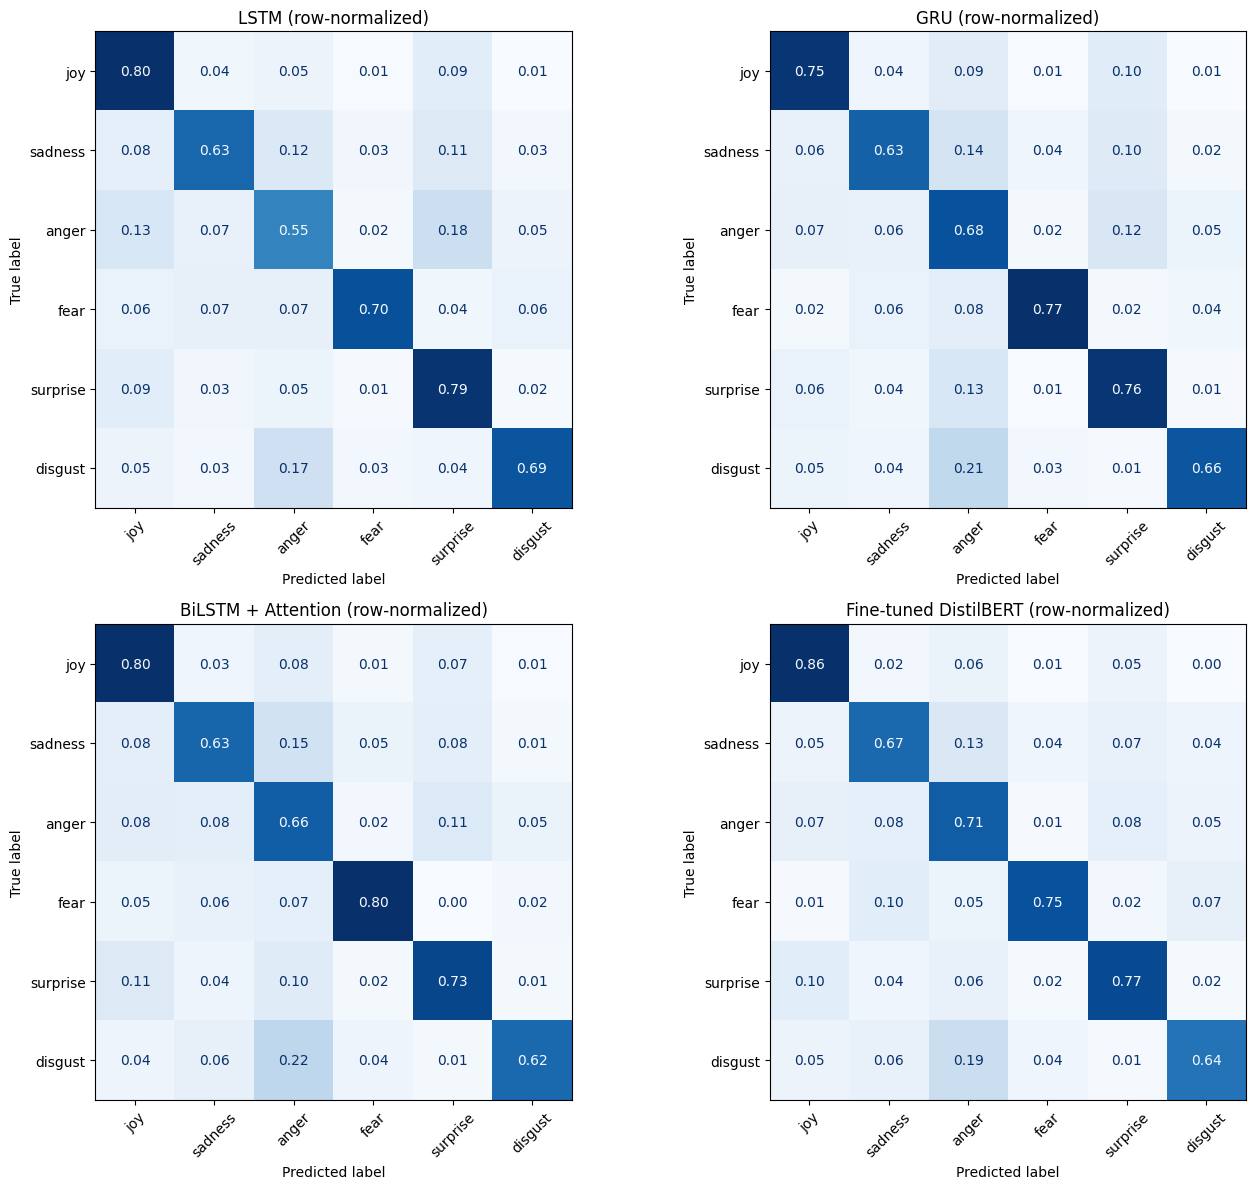

In [12]:
per_class_tables = {}
for key, r in results.items():
    predictions = r["test_probs"].argmax(axis=1)
    report = classification_report(y_test, predictions, target_names=EMOTIONS, output_dict=True, zero_division=0, digits=3)
    table = pd.DataFrame({e: {"precision": report[e]["precision"], "recall": report[e]["recall"], "F1": report[e]["f1-score"],
                              "support": int(report[e]["support"])} for e in EMOTIONS}).T
    per_class_tables[key] = table
    print("=" * 70)
    print(f"{r['label']} | test accuracy {r['test']['accuracy']:.4f} | macro precision {r['test']['precision']:.4f} | "
          f"macro recall {r['test']['recall']:.4f} | macro F1 {r['test']['f1']:.4f}")
    display(table.round(3))

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for axis, (key, r) in zip(axes.flat, results.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, r["test_probs"].argmax(axis=1), labels=np.arange(NUM_CLASSES), display_labels=EMOTIONS,
                                            normalize="true", xticks_rotation=45, cmap="Blues", colorbar=False, values_format=".2f", ax=axis)
    axis.set_title(f"{r['label']} (row-normalized)")
plt.tight_layout()
plt.show()

## 13. Compare the four architectures
The validation macro-F1 chooses the deployment model, and the test results are the final comparison.

,model,test accuracy,test macro precision,test macro recall,test macro F1,val macro F1,parameters (M),train time (min)
0,Fine-tuned DistilBERT,0.7950,0.6618,0.7325,0.6916,0.6858,66.9581,3.5759
1,GRU,0.7280,0.6126,0.7080,0.6499,0.6414,2.2458,0.4450
2,BiLSTM + Attention,0.7435,0.6130,0.7060,0.6499,0.6401,2.4103,0.9637
3,LSTM,0.7363,0.6121,0.6939,0.6422,0.6323,2.2752,0.5644


best model on validation macro-F1: Fine-tuned DistilBERT


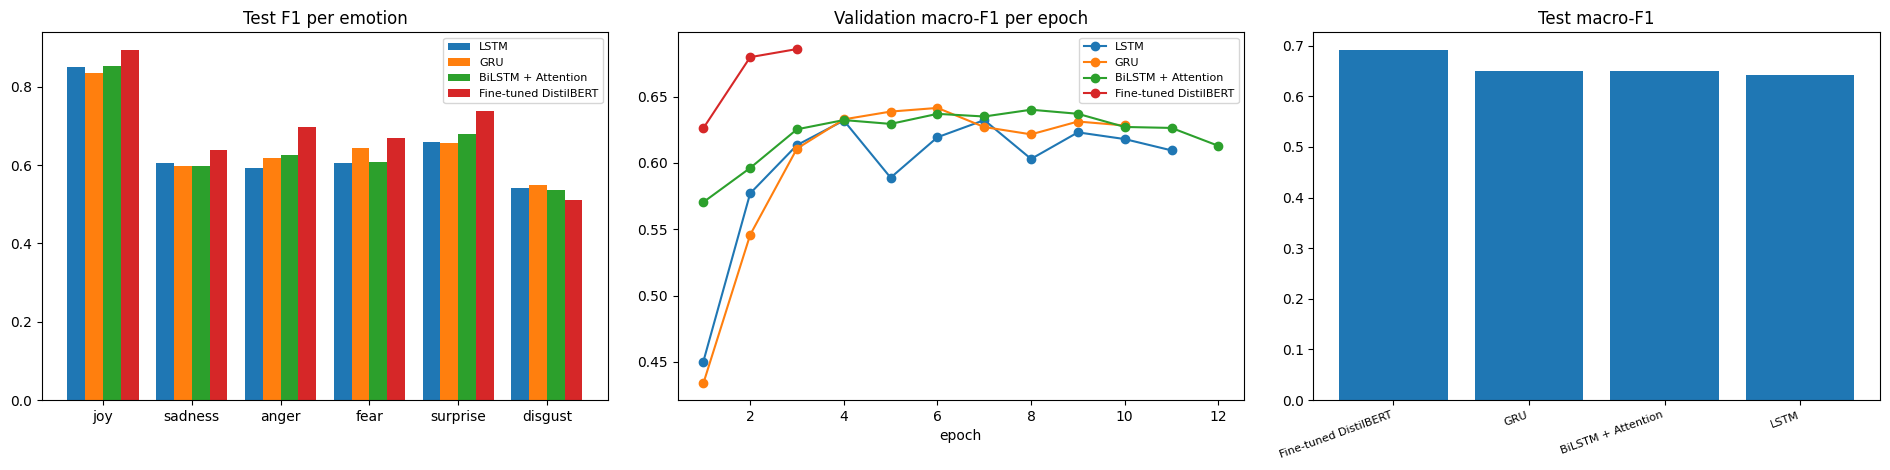

1) Best test macro-F1: transformer (0.692); accuracy 0.795.
2) GRU vs LSTM: 0.650 vs 0.642 macro-F1 with similar size; the GRU has fewer parameters (2.25M vs 2.28M).
3) Effect of bidirectional reading and attention: LSTM 0.642 -> BiLSTM + Attention 0.650 macro-F1 (+0.8 points).
4) Transformer vs best model built from scratch: 0.692 vs 0.650 macro-F1, 67M parameters and 3.6 min of training.
5) With Fine-tuned DistilBERT, the hardest emotion is disgust (F1 0.510) and the easiest is joy (F1 0.894).
6) Caveat: GoEmotions labels come from three annotators who often disagree and the comments are short, so the accuracy ceiling is limited; results are from one split and one seed.


In [13]:
summary = pd.DataFrame([{
    "model": r["label"], "test accuracy": r["test"]["accuracy"], "test macro precision": r["test"]["precision"],
    "test macro recall": r["test"]["recall"], "test macro F1": r["test"]["f1"], "val macro F1": r["val"]["f1"],
    "parameters (M)": r["params"] / 1e6, "train time (min)": r["train_seconds"] / 60, "key": key,
} for key, r in results.items()]).sort_values("val macro F1", ascending=False).reset_index(drop=True)
display(summary.drop(columns="key").round(4))
best_key = summary.loc[0, "key"]
print("best model on validation macro-F1:", results[best_key]["label"])

fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
x = np.arange(len(EMOTIONS))
for i, key in enumerate(results):
    axes[0].bar(x + (i - 1.5) * 0.2, per_class_tables[key]["F1"], 0.2, label=results[key]["label"])
axes[0].set_xticks(x)
axes[0].set_xticklabels(EMOTIONS)
axes[0].set_title("Test F1 per emotion")
axes[0].legend(fontsize=8)
for key, r in results.items():
    axes[1].plot([h["epoch"] for h in r["history"]], [h["val_f1"] for h in r["history"]], marker="o", label=r["label"])
axes[1].set_title("Validation macro-F1 per epoch")
axes[1].set_xlabel("epoch")
axes[1].legend(fontsize=8)
axes[2].bar(range(len(summary)), summary["test macro F1"], color="tab:blue")
axes[2].set_xticks(range(len(summary)))
axes[2].set_xticklabels(summary["model"], rotation=20, ha="right", fontsize=8)
axes[2].set_title("Test macro-F1")
plt.tight_layout()
plt.show()

f1 = {k: r["test"]["f1"] for k, r in results.items()}
acc = {k: r["test"]["accuracy"] for k, r in results.items()}
print(f"1) Best test macro-F1: {max(f1, key=f1.get)} ({max(f1.values()):.3f}); accuracy {acc[max(f1, key=f1.get)]:.3f}.")
print(f"2) GRU vs LSTM: {f1['gru']:.3f} vs {f1['lstm']:.3f} macro-F1 with similar size; the GRU has fewer parameters ({results['gru']['params'] / 1e6:.2f}M vs {results['lstm']['params'] / 1e6:.2f}M).")
print(f"3) Effect of bidirectional reading and attention: LSTM {f1['lstm']:.3f} -> BiLSTM + Attention {f1['bilstm_att']:.3f} macro-F1 "
      f"({(f1['bilstm_att'] - f1['lstm']) * 100:+.1f} points).")
print(f"4) Transformer vs best model built from scratch: {f1['transformer']:.3f} vs {max(f1['lstm'], f1['gru'], f1['bilstm_att']):.3f} macro-F1, "
      f"{results['transformer']['params'] / 1e6:.0f}M parameters and {results['transformer']['train_seconds'] / 60:.1f} min of training.")
worst = per_class_tables[best_key]["F1"].idxmin()
best_class = per_class_tables[best_key]["F1"].idxmax()
print(f"5) With {results[best_key]['label']}, the hardest emotion is {worst} (F1 {per_class_tables[best_key].loc[worst, 'F1']:.3f}) and the easiest is "
      f"{best_class} (F1 {per_class_tables[best_key].loc[best_class, 'F1']:.3f}).")
print("6) Caveat: GoEmotions labels come from three annotators who often disagree and the comments are short, so the accuracy ceiling is limited; "
      "results are from one split and one seed.")

## 14. Plot attention heatmaps to explain the predictions
For the BiLSTM + Attention model, the attention weight of every word shows how much that word contributed to the prediction. The heatmaps below show correctly and wrongly classified test comments, and the table lists the words that receive the most attention for each predicted emotion.

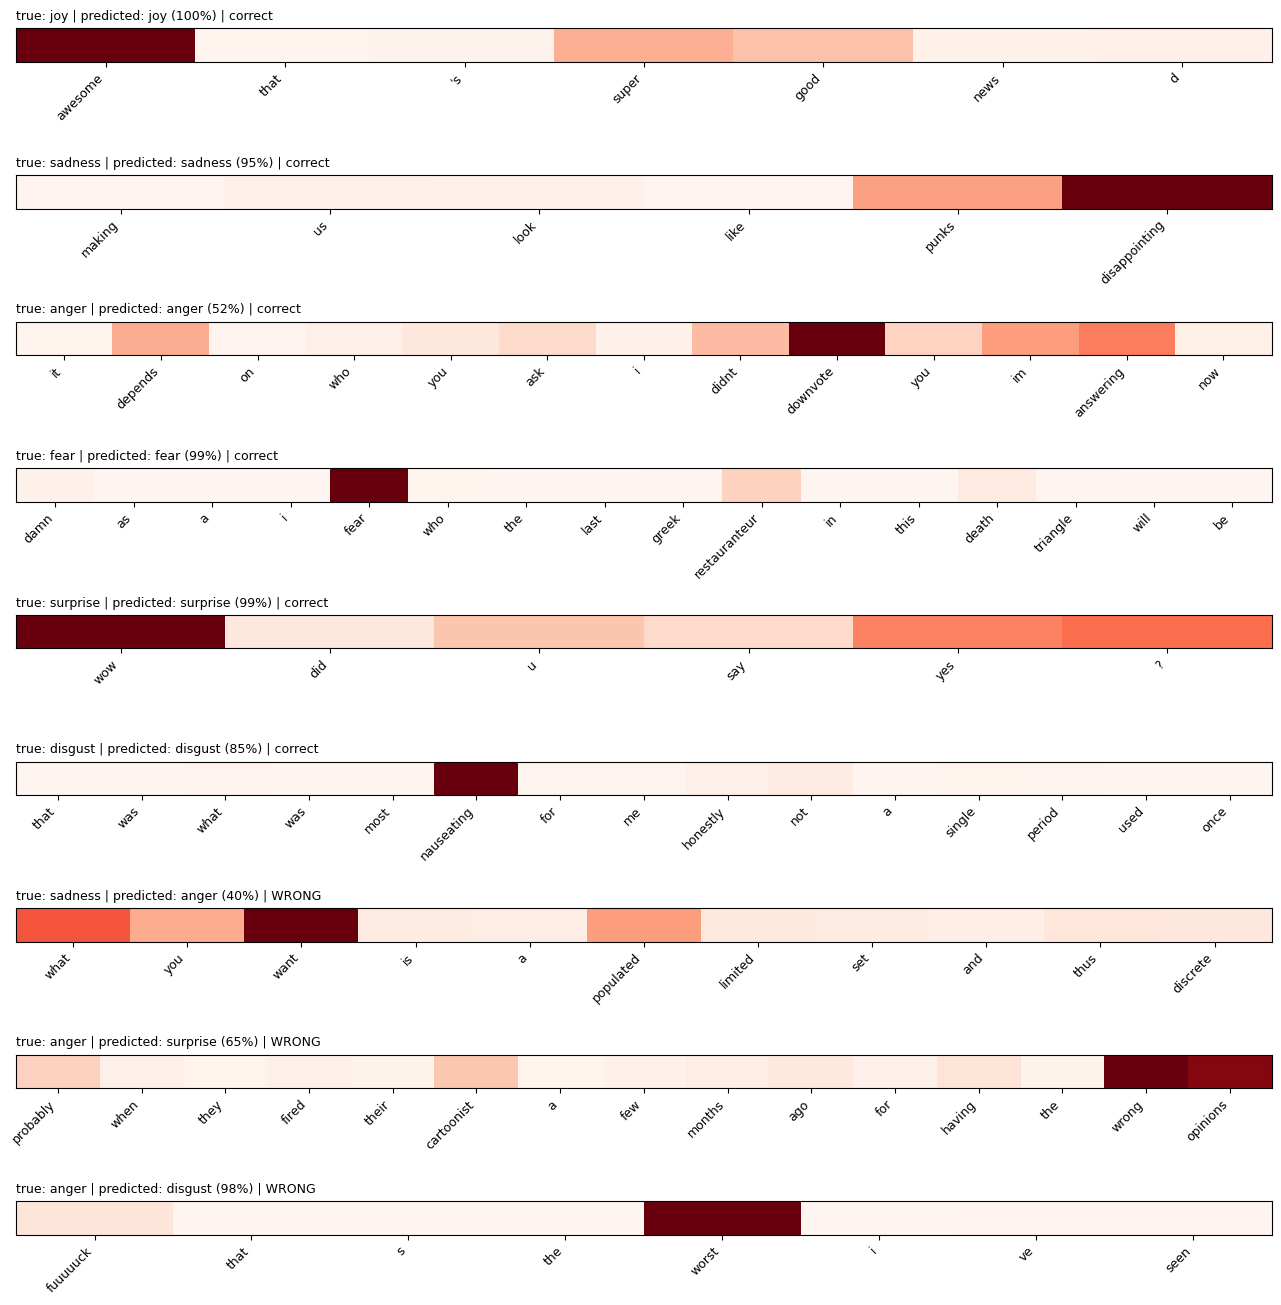

,words with the highest mean attention (appearing at least 5 times)
joy,"cheers, beautiful, hilarious, hopefully, thank..."
sadness,"upset, regret, wasted, sad, cry, sadly, awkwar..."
anger,"hell, angry, frustrating, fuck, annoying, suck..."
fear,"creepy, worried, scary, worry, fear, afraid, h..."
surprise,"surprise, surprised, curious, confused, realiz..."
disgust,"worse, worst, disgusting, weird, awful, ?, n't..."


In [14]:
def encode_for_rnn(texts):
    token_lists = [clean_tokens(t)[:MAX_LEN] for t in texts]
    X, lengths = pad_sequences(texts_to_ids(token_lists), MAX_LEN)
    return token_lists, torch.from_numpy(X), torch.from_numpy(lengths)

@torch.no_grad()
def attention_for_texts(texts):
    model = models["bilstm_att"]
    model.eval()
    token_lists, X, lengths = encode_for_rnn(texts)
    logits, weights = model(X.to(device), lengths.to(device), return_attention=True)
    probs = F.softmax(logits.float(), dim=1).cpu().numpy()
    weights = weights.cpu().numpy()
    return [(tokens, weights[i][:len(tokens)], probs[i]) for i, tokens in enumerate(token_lists)]

att_probs = results["bilstm_att"]["test_probs"]
att_pred = att_probs.argmax(axis=1)
short = [i for i in range(len(test)) if 6 <= len(test.at[i, "tokens"]) <= 16]
rng = random.Random(SEED)
chosen = []
for class_id in range(NUM_CLASSES):
    options = [i for i in short if y_test[i] == class_id and att_pred[i] == class_id]
    if options:
        chosen.append(rng.choice(options))
wrong = [i for i in short if att_pred[i] != y_test[i]]
chosen += rng.sample(wrong, min(3, len(wrong)))

analysis = attention_for_texts([test.at[i, "text"] for i in chosen])
fig, axes = plt.subplots(len(chosen), 1, figsize=(13, 1.35 * len(chosen) + 1))
axes = np.atleast_1d(axes)
for axis, i, (tokens, weights, probs) in zip(axes, chosen, analysis):
    axis.imshow(weights[None, :], aspect="auto", cmap="Reds", vmin=0, vmax=max(weights.max(), 1e-6))
    axis.set_yticks([])
    axis.set_xticks(range(len(tokens)))
    axis.set_xticklabels(tokens, rotation=45, ha="right", fontsize=9)
    verdict = "correct" if att_pred[i] == y_test[i] else "WRONG"
    axis.set_title(f"true: {EMOTIONS[y_test[i]]} | predicted: {EMOTIONS[int(probs.argmax())]} ({probs.max():.0%}) | {verdict}", fontsize=9, loc="left")
plt.tight_layout()
plt.show()

def attention_html(tokens, weights):
    scale = max(weights.max(), 1e-6)
    spans = [f'<span style="background:rgba(217,83,79,{0.08 + 0.85 * w / scale:.2f});padding:2px 4px;border-radius:3px;margin:1px">{html.escape(t)}</span>'
             for t, w in zip(tokens, weights)]
    return " ".join(spans)

for i, (tokens, weights, probs) in list(zip(chosen, analysis))[:4]:
    display(HTML(f"<b>{EMOTIONS[int(probs.argmax())]}</b> ({probs.max():.0%}): " + attention_html(tokens, weights)))

word_sum, word_count = defaultdict(lambda: defaultdict(float)), defaultdict(lambda: defaultdict(int))
all_analysis = attention_for_texts(test["text"].tolist())
for (tokens, weights, probs) in all_analysis:
    predicted = int(probs.argmax())
    for token, weight in zip(tokens, weights):
        word_sum[predicted][token] += weight
        word_count[predicted][token] += 1
top_words = {}
for class_id, emotion in enumerate(EMOTIONS):
    ranked = sorted(((word_sum[class_id][w] / word_count[class_id][w], w) for w in word_sum[class_id] if word_count[class_id][w] >= 5), reverse=True)
    top_words[emotion] = ", ".join(w for _, w in ranked[:10])
display(pd.DataFrame({"words with the highest mean attention (appearing at least 5 times)": top_words}))

## 15. Save the best model

In [15]:
summary.drop(columns="key").to_csv(WORK / "model_comparison.csv", index=False)
(WORK / "emotions.json").write_text(json.dumps(EMOTIONS))
for key in results:
    per_class_tables[key].to_csv(WORK / f"per_class_{key}.csv")

if best_key == "transformer":
    SAVE_DIR = WORK / "best_emotion_transformer"
    models["transformer"].save_pretrained(SAVE_DIR)
    tr_tokenizer.save_pretrained(SAVE_DIR)
    print("transformer saved to", SAVE_DIR)
else:
    SAVE_PATH = WORK / f"best_{best_key}.pt"
    torch.save({"key": best_key, "state_dict": copy_state(models[best_key]), "word_index": word_index, "emotions": EMOTIONS,
                "embed_dim": EMBED_DIM, "max_len": MAX_LEN}, SAVE_PATH)
    print("model saved to", SAVE_PATH, f"({SAVE_PATH.stat().st_size / 1e6:.1f} MB)")
torch.save({"state_dict": copy_state(models["bilstm_att"]), "word_index": word_index, "emotions": EMOTIONS, "embed_dim": EMBED_DIM, "max_len": MAX_LEN},
           WORK / "bilstm_attention_for_explanations.pt")
print(f"total notebook runtime: {(time.time() - T0) / 60:.1f} min")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

transformer saved to /kaggle/working/best_emotion_transformer
total notebook runtime: 16.2 min


## 16. Deploy with Gradio
The app returns the dominant emotion, a confidence bar chart over all six classes, and a highlight of the words the BiLSTM + Attention model focused on. The prediction comes from the best model chosen on validation data. The attention highlight is always taken from the BiLSTM + Attention model, because it is the model that exposes attention weights.

In [ ]:
try:
    import gradio as gr
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gradio"], check=True)
    import gradio as gr

@torch.no_grad()
def predict_emotion_probs(text, model_key):
    model = models[model_key]
    model.eval()
    if model_key == "transformer":
        encoding = tr_tokenizer(text, truncation=True, max_length=TR_MAX_LEN, return_tensors="pt")
        logits = model(**{k: v.to(device) for k, v in encoding.items()}).logits
        return F.softmax(logits.float(), dim=1)[0].cpu().numpy()
    _, X, lengths = encode_for_rnn([text])
    return F.softmax(model(X.to(device), lengths.to(device)).float(), dim=1)[0].cpu().numpy()

def analyze_emotion(text):
    if text is None or not text.strip():
        return "Enter some text.", None, ""
    probs = predict_emotion_probs(text, best_key)
    top = int(probs.argmax())
    figure, axis = plt.subplots(figsize=(6, 3.4))
    axis.barh(EMOTIONS[::-1], probs[::-1], color=[EMOTION_COLORS[e] for e in EMOTIONS[::-1]])
    axis.set_xlim(0, 1)
    axis.set_xlabel("confidence")
    axis.set_title("Confidence per emotion")
    for position, value in enumerate(probs[::-1]):
        axis.text(min(value + 0.02, 0.88), position, f"{value:.0%}", va="center")
    plt.tight_layout()
    explanation = "<i>No recognizable words to explain.</i>"
    tokens, weights, _ = attention_for_texts([text])[0]
    if tokens:
        explanation = "<b>Words the BiLSTM + Attention model focused on:</b><br>" + attention_html(tokens, weights)
    return f"{EMOTIONS[top].upper()}  ({probs[top]:.1%} confidence)", figure, explanation

demo = gr.Interface(
    fn=analyze_emotion,
    inputs=gr.Textbox(lines=4, label="Text", placeholder="Type how you feel or paste a comment..."),
    outputs=[gr.Textbox(label="Dominant emotion"), gr.Plot(label="Confidence across the 6 emotions"), gr.HTML(label="Attention explanation")],
    title="Emotion Classifier",
    description=f"Predicts joy, sadness, anger, fear, surprise, or disgust with {results[best_key]['label']}.",
    examples=[["I can't believe they cancelled my flight again, this is unacceptable!"],
              ["Thank you so much, this made my whole week!"],
              ["I'm terrified of what the results will be tomorrow."],
              ["Wow, I never expected that to happen!"]],
)
try:
    demo.launch(share=False, prevent_thread_lock=True)
except Exception as error:
    print("share link unavailable:", error)
    demo.launch(prevent_thread_lock=True)